# Check the control cells

Every effect in a screen is measured against the controls, so before testing it pays to check that the cells
used as controls behave alike. This notebook runs crispyx's two checks on the targeted CRISPRi screen of
Feng et al. (2026, *Cell Genomics*, [doi:10.1016/j.xgen.2025.101076](https://doi.org/10.1016/j.xgen.2025.101076)),
where few cells have a detected guide:

1. **Do the non-targeting guides agree?** `cx.pp.control_guide_correlation` correlates each guide's
   deviation from the guides' average profile; `cx.pl.control_guide_correlation` draws the matrix.
2. **May cells without a detected guide join the controls?** The authors pool these "unassigned" cells
   with the non-targeting ones. `cx.pp.compare_controls` tests each non-targeting guide against the
   unassigned cells and, as a yardstick, against the other non-targeting guides.

[Quality control](../quality_control.rst#check-the-control-cells) describes both functions.

> **Key results**
>
> - The 20 non-targeting guides agree with one another: their deviations hardly correlate (median r -0.02).
> - The unassigned cells differ from them. Each guide differs from the unassigned cells in 132-438 genes,
>   against 0-16 from the other guides; pooled, 849 genes differ.
> - Among those genes are the CRISPRi construct, lower in the unassigned cells, and the screen's own
>   targets: many unassigned cells carry less CRISPRi machinery or an undetected guide. The non-targeting
>   cells are the safer controls.

The input is `tutorial_outputs/FengTS_counts.h5ad`, the raw counts written by
[the Feng tutorial](residual_effects_targeted_feng.ipynb) (1.16 million cells). The notebook takes about
20 minutes on 32 cores.

In [1]:
import os

os.environ.setdefault('TQDM_DISABLE', '1')
# gene symbols repeat in this screen; worker processes inherit this filter
os.environ['PYTHONWARNINGS'] = 'ignore:Variable names are not unique'

import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Paths stay relative to this notebook's directory so that the paths crispyx
# echoes in its output are the same on every machine.
ROOT = Path('../..')
sys.path.insert(0, str(ROOT / 'src'))
warnings.filterwarnings('ignore', message='A worker stopped while some jobs')
warnings.filterwarnings('ignore', message='Variable names are not unique')  # gene symbols repeat
warnings.filterwarnings('ignore', message='pb.aggregate: 1 cells have missing grouping values')  # no metadata
import crispyx as cx

OUTPUT_DIR = Path('tutorial_outputs')
WORK_DIR = OUTPUT_DIR / 'control_checks'
counts_path = OUTPUT_DIR / 'FengTS_counts.h5ad'
N_JOBS, MEMORY_GB = 16, 64
pd.set_option('display.width', 160)
print(f'crispyx {cx.__version__}')

crispyx 0.2.3


## The control cells

`Guide_Call` names each cell's guide, or `unassigned` when none was detected. The non-targeting guides
start with `NonTarget`; `inlet` is the 10x lane (142 of them).

In [2]:
obs = cx.load_obs(counts_path)
guides = obs['Guide_Call'].astype(str)
controls = sorted(g for g in guides.unique() if g.startswith('NonTarget'))
n_nontarget = guides.isin(controls).sum()
n_unassigned = (guides == 'unassigned').sum()
print(f'{len(obs):,} cells; {len(controls)} non-targeting guides on {n_nontarget:,} cells, '
      f'{n_unassigned:,} unassigned cells ({n_unassigned / (n_nontarget + n_unassigned):.0%} of the controls)')
guides[guides.isin(controls)].value_counts().describe().round(0).to_frame('cells per guide').T

1,161,865 cells; 20 non-targeting guides on 8,241 cells, 526,842 unassigned cells (98% of the controls)


,count,mean,std,min,25%,50%,75%,max
cells per guide,20.0,412.0,289.0,25.0,203.0,333.0,678.0,992.0


## 1. Do the non-targeting guides agree?

`control_guide_correlation` sums each guide's counts over its cells in one streaming pass, normalises them
to `log1p` counts per 10,000, and correlates each guide's deviation from the guides' average over the 2,000
most expressed genes. Guides that differ only by noise correlate near 0; a block of correlated guides
shares variation (a batch, an off-target effect) that a test reads as signal when those guides are the
controls. With `reference='unassigned'` the unassigned cells are one more profile, marked "(reference)"; the number
in brackets is each profile's cells.

21 profiles in 15 s
between guides: median r -0.02, range [-0.38, +0.26]


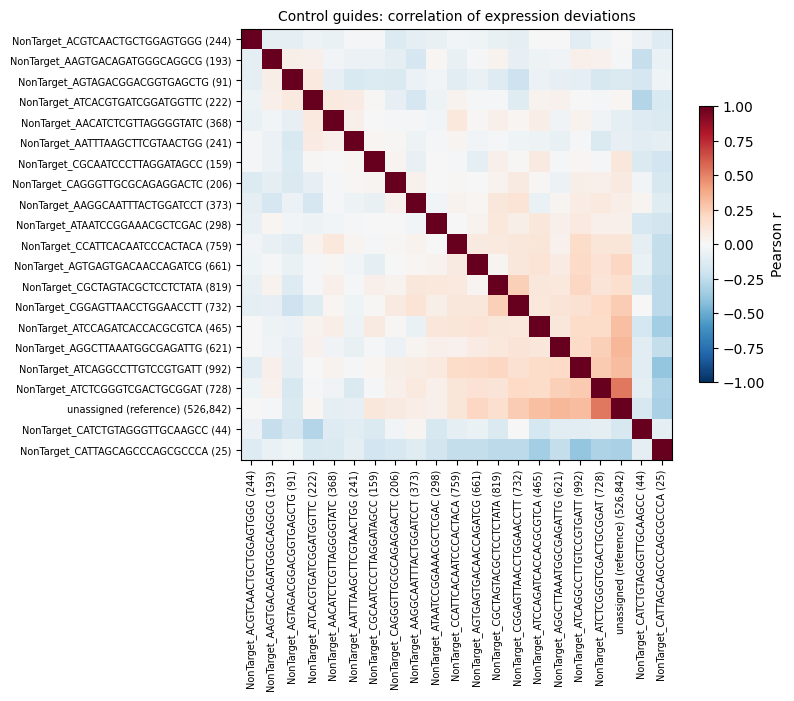

In [3]:
t = time.time()
corr = cx.pp.control_guide_correlation(counts_path, guide_column='Guide_Call', controls=controls,
                                       reference='unassigned')
print(f'{len(corr)} profiles in {time.time() - t:.0f} s')

n = len(corr) - 1  # the last profile is the unassigned cells
between = corr.iloc[:n, :n].to_numpy()[np.triu_indices(n, 1)]
print(f'between guides: median r {np.median(between):+.2f}, range [{between.min():+.2f}, {between.max():+.2f}]')
fig, ax = plt.subplots(figsize=(8, 7))
cx.pl.control_guide_correlation(corr, ax=ax)
fig.tight_layout()

No block of guides stands out: they differ by noise. The weak pattern along the diagonal comes from the
guides' sizes. Each deviation is taken from the unweighted average of the guides, which carries the noise of
the smallest ones (25 and 44 cells); every well-measured profile deviates from that noise the same way, so the
larger guides and the unassigned cells correlate mildly with one another and negatively with the small
guides. Correlations cannot say whether the unassigned cells differ from the guides; the test below does.

## 2. May the unassigned cells join the controls?

`compare_controls` runs `nb_glm_test` for each non-targeting guide twice: against the unassigned cells,
and against the other non-targeting guides. The second comparison is the yardstick: two pools of genuine
controls also differ, through guide-to-guide differences and any miscalibration of the test. If the
unassigned cells are like the guides, a guide gets about as many hits against them as against the other
guides.

Cells of one inlet share a library preparation, so the test runs on **pseudo-bulk** units: counts summed per
guide and inlet (units of at least 5 cells; one cell without metadata is left out), DESeq2's size
factors, and the inlet as a covariate. On
pseudo-bulk the test is calibrated and fast (see
[Cell level or pseudo-bulk?](../nb_glm.rst#cell-level-or-pseudo-bulk)); single cells
with an inlet covariate would hold the 527,000 unassigned cells in memory for every fit.

In [4]:
t = time.time()
units = cx.pb.aggregate(counts_path, groupby=['Guide_Call', 'inlet'], method='sum',
                        perturbations=[*controls, 'unassigned'], min_cells=5, gene_name_column='gene_name',
                        output_path=OUTPUT_DIR / 'FengTS_control_units.h5ad', memory_limit_gb=MEMORY_GB,
                        verbose=False, force=True)
unit_obs = cx.load_obs(units.path)
is_unassigned = unit_obs['Guide_Call'].astype(str) == 'unassigned'
print(f'{len(unit_obs):,} units in {time.time() - t:.0f} s: {is_unassigned.sum()} unassigned '
      f'({unit_obs.loc[is_unassigned, "n_cells"].median():,.0f} cells each, median), '
      f'{(~is_unassigned).sum()} non-targeting ({unit_obs.loc[~is_unassigned, "n_cells"].median():.0f} cells each)')

825 units in 38 s: 142 unassigned (3,710 cells each, median), 683 non-targeting (6 cells each)


In [5]:
t = time.time()
table = cx.pp.compare_controls(units.path, guide_column='Guide_Call', controls=controls, reference='unassigned',
                               work_dir=WORK_DIR, min_cells=2, covariates=['inlet'], size_factor_method='deseq2',
                               gene_name_column='gene_name', n_jobs=N_JOBS, memory_limit_gb=MEMORY_GB,
                               verbose=False)
print(f'{time.time() - t:.0f} s; "cells" counts units here')
table.round(2)

937 s; "cells" counts units here


,cells,vs reference: hits,vs reference: |z|>3 %,vs other controls: hits,vs other controls: |z|>3 %
Guide_Call,,,,,
NonTarget_AACATCTCGTTAGGGGTATC,16,226,1.83,0.0,0.19
NonTarget_AAGGCAATTTACTGGATCCT,19,241,1.92,0.0,0.23
NonTarget_AAGTGACAGATGGGCAGGCG,2,132,1.66,0.0,0.16
NonTarget_AATTTAAGCTTCGTAACTGG,5,186,1.68,0.0,0.23
NonTarget_ACGTCAACTGCTGGAGTGGG,6,167,1.62,2.0,0.19
NonTarget_AGGCTTAAATGGCGAGATTG,64,187,1.48,0.0,0.15
NonTarget_AGTAGACGGACGGTGAGCTG,2,169,1.95,0.0,0.38
NonTarget_AGTGAGTGACAACCAGATCG,64,438,2.30,4.0,0.21
NonTarget_ATAATCCGGAAACGCTCGAC,6,201,1.94,0.0,0.31


17 of the 20 guides have at least two units and are tested. Against the other guides almost no gene differs, and about 0.2 % of genes have |z| > 3, close to the
0.27 % of a calibrated test. Against the unassigned cells each guide differs in a few hundred genes,
however few units it has.

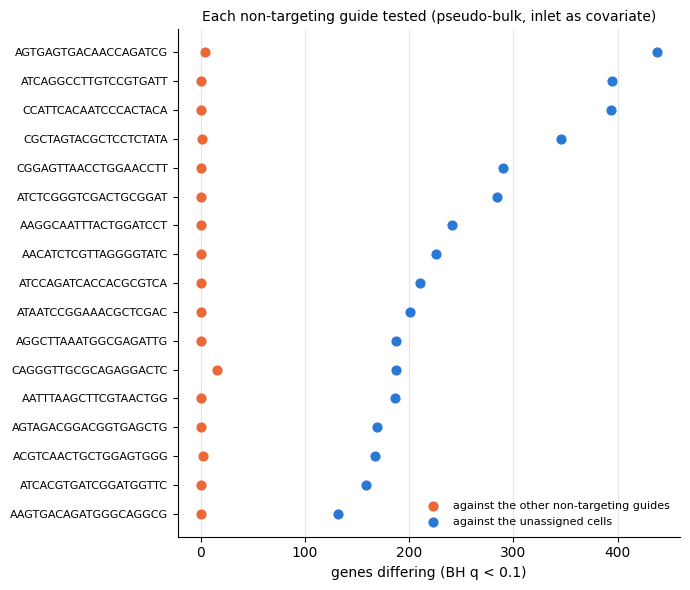

In [6]:
per_guide = table.drop(index='all control guides').sort_values('vs reference: hits')
y = np.arange(len(per_guide))
fig, ax = plt.subplots(figsize=(7, 6))
for column, color, label in (('vs other controls: hits', '#eb6834', 'against the other non-targeting guides'),
                             ('vs reference: hits', '#2a78d6', 'against the unassigned cells')):
    ax.scatter(per_guide[column], y, s=40, color=color, label=label, zorder=3)
ax.set_yticks(y, [g.removeprefix('NonTarget_') for g in per_guide.index], fontsize=8)
ax.set_xlabel('genes differing (BH q < 0.1)')
ax.set_title('Each non-targeting guide tested (pseudo-bulk, inlet as covariate)', fontsize=10)
ax.grid(axis='x', color='0.9', zorder=0)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='lower right', fontsize=8)
fig.tight_layout()

### Which genes differ?

The pooled comparison (all non-targeting units against the unassigned ones) is in
`pooled_vs_reference.h5ad`. A positive z means higher in the non-targeting cells. `dCas9-KRAB-MeCP2`
is the CRISPRi construct, counted as a gene in this screen.

In [7]:
pooled = cx.pl.rank_genes_groups_df(WORK_DIR / 'pooled_vs_reference.h5ad', 'controls')
hits = pooled[pooled['pvals_adj'] < 0.1]
print(f'{len(hits)} of {pooled["scores"].notna().sum():,} genes differ')
hits.reindex(hits['scores'].abs().sort_values(ascending=False).index).head(15)[
    ['names', 'scores', 'logfoldchanges', 'pvals_adj']].round(3)

849 of 26,536 genes differ


,names,scores,logfoldchanges,pvals_adj
0,MEG8,-17.532,-3.397,0.0
1,MEG3,-17.276,-4.245,0.0
2,dCas9-KRAB-MeCP2,13.249,0.728,0.0
3,ZNF728,-11.665,-1.318,0.0
4,NPTX1,-9.899,-2.032,0.0
5,ZNF208,-9.813,-1.542,0.0
6,XIST,-9.120,-1.767,0.0
7,AP1S2,8.770,0.178,0.0
8,TRDN,-8.661,-0.604,0.0
9,RBBP7,8.530,0.171,0.0


If some unassigned cells carry a targeting guide that was not detected, the screen's targets are knocked
down in them, so they should be lower in the unassigned cells (higher in the non-targeting ones) more often
than other genes are.

In [8]:
targets = {g.split('_')[0] for g in guides.unique()} - {'NonTarget', 'unassigned'}
tested = pooled[pooled['scores'].notna()]
is_target = tested['names'].isin(targets)
summary = pd.DataFrame({
    'genes': [is_target.sum(), (~is_target).sum()],
    'differ (q < 0.1)': [(tested.loc[is_target, 'pvals_adj'] < 0.1).mean(),
                         (tested.loc[~is_target, 'pvals_adj'] < 0.1).mean()],
    'higher in non-targeting cells': [(tested.loc[is_target, 'scores'] > 0).mean(),
                                      (tested.loc[~is_target, 'scores'] > 0).mean()],
}, index=['targets of the screen', 'other genes'])
summary.style.format({'differ (q < 0.1)': '{:.1%}', 'higher in non-targeting cells': '{:.0%}'})

,genes,differ (q < 0.1),higher in non-targeting cells
targets of the screen,439,5.2%,68%
other genes,26097,3.2%,55%


## Conclusion

The non-targeting guides agree with one another, and the unassigned cells differ from all of them: less
CRISPRi construct, and lower expression of the screen's targets. Many unassigned cells likely carry less
CRISPRi machinery or a guide that was not detected, so pooling them into the controls dilutes effects and
adds differences of their own. Here the non-targeting cells are the safer controls; with few of them,
pseudo-bulk per guide and inlet keeps the test calibrated.

**Single cells, no covariate.** `compare_controls` takes the cells directly too
(`compare_controls(counts_path, ...)`); on this screen, though, single cells without the inlet are
miscalibrated (see [Cell level or pseudo-bulk?](../nb_glm.rst#cell-level-or-pseudo-bulk)),
so the yardstick itself shows many hits. Check that column before reading the other.